# One-stage anchor-free detector: YOLO11

COCO-pretrained YOLO11s (Ultralytics) on the adopted split: training setup with its augmentation, history, results, the search range and selected settings, how grid locations are assigned to objects without anchors, failure analysis, and a comparison by object size with the tuned anchor-based detectors of `02_two_stage.ipynb` and `03_one_stage_anchor.ipynb`.

| # | Section |
| --- | --- |
| 1 | [Setup](#1-setup) |
| 2 | [Training setup](#2-training-setup) |
| 3 | [Training history](#3-training-history) |
| 4 | [Results](#4-results) |
| 5 | [Experiments](#5-experiments) |
| 6 | [Inside the model](#6-inside-the-model) |
| 7 | [Failure analysis](#7-failure-analysis) |
| 8 | [Comparison](#8-comparison) |
| 9 | [Conclusions](#9-conclusions) |

## 1. Setup

Imports, data root from `DATA_ROOT`, the shared plot theme, the annotations of the adopted split, and the rows of `experiments/results.csv`, the source of truth for reported numbers. No cell needs a checkpoint.

In [1]:
import json
import sys
import tomllib
from pathlib import Path

import numpy as np
import polars as pl
import torch
from decouple import AutoConfig
from IPython.display import display

# make the repository root importable when the kernel starts in notebooks/
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))
# decouple locates .env from the caller file, which is a temp file inside a kernel
config = AutoConfig(search_path=PROJECT_ROOT)

import matplotlib.pyplot as plt
from ultralytics.cfg import get_cfg

from src.data.annotations import load_annotations, load_split_clips
from src.data.boxes import convert_xywh_to_xyxy, explode_size_buckets
from src.data.classes import CLASS_NAMES
from src.data.dataset import load_frame_steps, select_frames
from src.evaluate import METRICS_FILE, PREDICTIONS_FILE
from src.evaluation.failure_analysis import (
    compute_recall_by_size,
    count_error_categories,
    find_best_f1_threshold,
    match_detections,
    select_error_examples,
)
from src.models.yolo import count_assignment_candidates
from src.training.experiment import CONFIG_FILE
from src.visualization.frames import plot_error_examples
from src.visualization.plots import plot_grouped_bars, plot_training_history
from src.visualization.style import set_plot_theme
from src.visualization.tables import compare_with_reference, load_run_histories

FAMILY = "yolo"
BASELINE = "yolo-baseline"

SEED = 42
set_plot_theme()
pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(200)

DATA_ROOT = Path(config("DATA_ROOT"))
TUNED_FASTER_RCNN = "faster_rcnn-giou_loss"
tables = load_annotations(DATA_ROOT, load_split_clips(PROJECT_ROOT / "config" / "data.toml"))
val_images = tables.images.filter(pl.col("split") == "val")
val_objects = tables.objects.filter(pl.col("split") == "val")
val_ignored = tables.ignored.filter(pl.col("split") == "val")
results = pl.read_csv(PROJECT_ROOT / "experiments" / "results.csv")
run_dirs = {row["experiment"]: PROJECT_ROOT / row["run_dir"] for row in results.iter_rows(named=True)}
run_configs = {e: tomllib.loads((d / CONFIG_FILE).read_text()) for e, d in run_dirs.items()}
run_metrics = {e: json.loads((d / METRICS_FILE).read_text()) for e, d in run_dirs.items()}
family_results = results.filter(pl.col("experiment").str.starts_with(f"{FAMILY}-"))
family_results.select("experiment", "run_dir", "seed", "machine", "is_dirty")

experiment,run_dir,seed,machine,is_dirty
str,str,i64,str,bool
"""yolo-baseline""","""runs/yolo-baseline/20261105-2326""",42,"""pc""",false
"""yolo-imgsz_1280""","""runs/yolo-imgsz_1280/20261107-1311""",42,"""pc""",false
"""yolo-tal_topk""","""runs/yolo-tal_topk/20261107-1422""",42,"""pc""",true
"""yolo-scale_025""","""runs/yolo-scale_025/20261108-0057""",42,"""pc""",false


Four YOLO11s runs on the PC. `yolo-tal_topk` is marked dirty only because the `results.csv` row of `imgsz_1280` was appended before it started; its code and config were committed.

## 2. Training setup

YOLO11s trains with Ultralytics at `imgsz` 1824, which resizes the longer frame side to 1824 px and gives the same object scale as the torchvision families (shorter side about 1024 px). Training hyperparameters not set in the config are Ultralytics defaults; the optimizer is set explicitly (AdamW) so that it cannot change with the number of iterations. Ultralytics accumulates gradients to a nominal batch of 64 images.

In [2]:
baseline_config = run_configs[BASELINE]
baseline_training = run_metrics[BASELINE]["training"]
training_fields = [
    "machine", "frame_step", "epochs", "batch_size", "effective_batch_size", "gpu_hours", "best_epoch",
]
pl.DataFrame(
    [("config", key, str(value)) for key, value in baseline_config.items() if not isinstance(value, dict)]
    + [
        ("training record", key, str(round(value, 2) if isinstance(value, float) else value))
        for key in training_fields
        for value in [baseline_training[key]]
    ],
    schema=["source", "setting", "value"],
    orient="row",
)

source,setting,value
str,str,str
"""config""","""arch""","""yolo11s"""
"""config""","""init""","""coco"""
"""config""","""train_frames""","""train_tuning"""
"""config""","""imgsz""","""1824"""
"""config""","""epochs""","""20"""
"""config""","""batch_size""","""2"""
"""config""","""optimizer""","""AdamW"""
"""config""","""lr""","""0.000833"""
"""config""","""momentum""","""0.9"""


- 20 epochs at `imgsz` 1824 with batch 2 took 1.12 GPU hours; Ultralytics accumulates gradients to an effective batch of 64. The best Ultralytics monitoring epoch is 7.
- AdamW at lr 0.000833, the value Ultralytics' `auto` optimizer picks for 8 classes, set explicitly.

**Augmentation caveat.** Ultralytics trains with its default augmentation, while the torchvision and Hugging Face families of notebooks 02, 03, and 05 train on unmodified frames. The table lists the augmentation settings of the YOLO runs: Ultralytics defaults (`ultralytics.cfg.get_cfg`) with the configured `close_mosaic` and `scale`.

In [3]:
AUGMENTATION_KEYS = [
    "mosaic", "close_mosaic", "fliplr", "flipud", "scale", "translate", "degrees", "shear",
    "perspective", "hsv_h", "hsv_s", "hsv_v", "mixup", "cutmix", "copy_paste", "erasing",
]
defaults = vars(get_cfg())
pl.DataFrame(
    {
        "setting": AUGMENTATION_KEYS,
        "ultralytics_default": [str(defaults[key]) for key in AUGMENTATION_KEYS],
        **{
            e: [str(run_configs[e].get(key, defaults[key])) for key in AUGMENTATION_KEYS]
            for e in family_results["experiment"]
        },
    }
)

setting,ultralytics_default,yolo-baseline,yolo-imgsz_1280,yolo-tal_topk,yolo-scale_025
str,str,str,str,str,str
"""mosaic""","""1.0""","""1.0""","""1.0""","""1.0""","""1.0"""
"""close_mosaic""","""10""","""10""","""10""","""10""","""10"""
"""fliplr""","""0.5""","""0.5""","""0.5""","""0.5""","""0.5"""
"""flipud""","""0.0""","""0.0""","""0.0""","""0.0""","""0.0"""
"""scale""","""0.5""","""0.5""","""0.5""","""0.5""","""0.25"""
"""translate""","""0.1""","""0.1""","""0.1""","""0.1""","""0.1"""
"""degrees""","""0.0""","""0.0""","""0.0""","""0.0""","""0.0"""
"""shear""","""0.0""","""0.0""","""0.0""","""0.0""","""0.0"""
"""perspective""","""0.0""","""0.0""","""0.0""","""0.0""","""0.0"""


- All YOLO runs train with mosaic (switched off for the last 10 epochs), horizontal flips (p 0.5), random scale (gain 0.5, 0.25 in `scale_025`) and translation (0.1), and HSV colour jitter. `erasing` applies to Ultralytics classification training only.
- The torchvision and Hugging Face families train on unmodified frames, so every cross-family comparison below confounds the model with the augmentation.

## 3. Training history

Ultralytics validates on val frames at step 5 after every epoch with its own evaluator; these framework metrics are for monitoring only (AGENTS.md), and `best.pt` is the epoch with the highest Ultralytics mAP@[.5:.95]. Reported metrics in section 4 come from the shared evaluator.

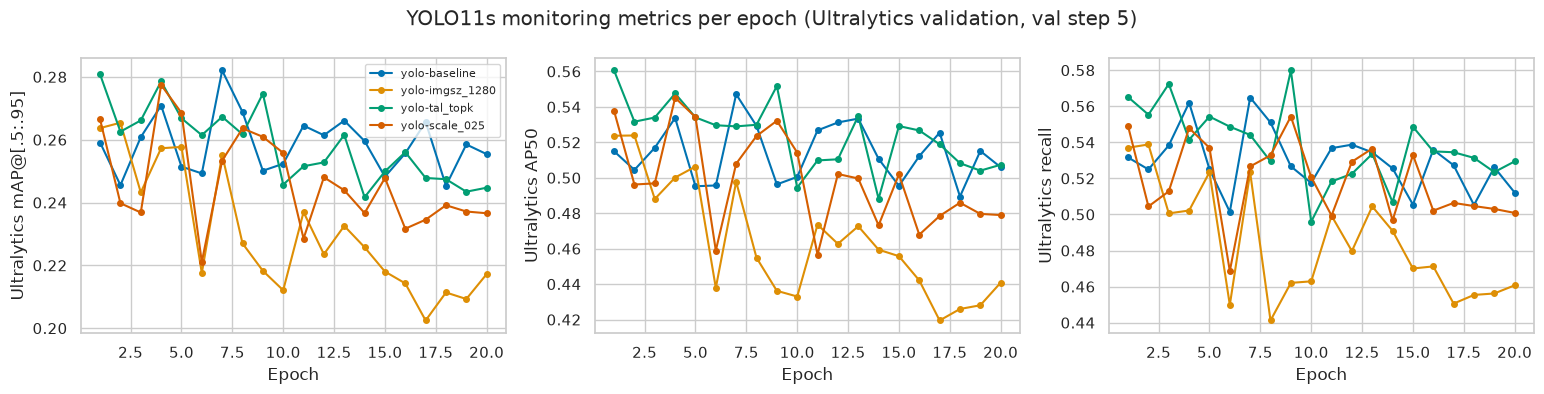

In [4]:
family_run_dirs = {e: run_dirs[e] for e in family_results["experiment"]}
histories = load_run_histories(family_run_dirs)
fig = plot_training_history(
    histories,
    {
        "metrics/mAP50-95(B)": "Ultralytics mAP@[.5:.95]",
        "metrics/mAP50(B)": "Ultralytics AP50",
        "metrics/recall(B)": "Ultralytics recall",
    },
    "YOLO11s monitoring metrics per epoch (Ultralytics validation, val step 5)",
)

- Ultralytics monitoring mAP jumps between epochs: the baseline ranges from 0.245 to 0.282 and peaks at epoch 7, with a mean change of 0.0115 from one epoch to the next.
- `imgsz_1280` declines after epoch 4 to about 0.21; the other runs drift down slowly after their early peaks.
- Switching mosaic off at epoch 11 brings no consistent change.

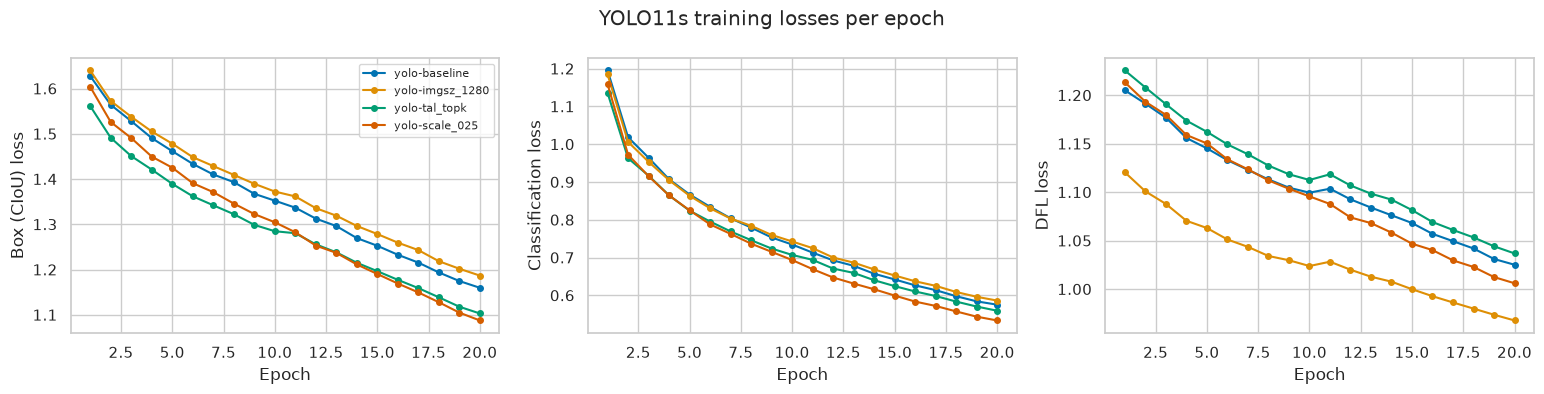

In [5]:
fig = plot_training_history(
    histories,
    {"train/box_loss": "Box (CIoU) loss", "train/cls_loss": "Classification loss", "train/dfl_loss": "DFL loss"},
    "YOLO11s training losses per epoch",
)

- All three losses fall steadily over the 20 epochs in every run, while monitoring mAP does not rise after the first epochs: as in the other families, the training fit keeps improving without a gain on val.
- `imgsz_1280` has the lowest DFL loss and `tal_topk` the lowest box loss in the first half; the losses are not comparable across settings that change the targets or the input size.

In [6]:
monitoring = "metrics/mAP50-95(B)"
histories.group_by("experiment", maintain_order=True).agg(
    pl.len().alias("epochs"),
    pl.col("epoch").get(pl.col(monitoring).arg_max()).alias("best_epoch"),
    pl.col(monitoring).max().round(4).alias("best_monitoring_map"),
    pl.col(monitoring).last().round(4).alias("last_monitoring_map"),
    pl.col(monitoring).diff().abs().mean().round(4).alias("mean_epoch_to_epoch_change"),
)

experiment,epochs,best_epoch,best_monitoring_map,last_monitoring_map,mean_epoch_to_epoch_change
str,u32,i64,f64,f64,f64
"""yolo-baseline""",20,7,0.282,0.2554,0.0115
"""yolo-imgsz_1280""",20,2,0.2654,0.2172,0.0135
"""yolo-tal_topk""",20,1,0.2808,0.2447,0.0089
"""yolo-scale_025""",20,4,0.2774,0.2366,0.0143


Best monitoring epochs range from 1 (`tal_topk`) to 7 (baseline); epoch-to-epoch changes of 0.009 to 0.014 make single-epoch differences between runs unreliable.

## 4. Results

Rows of `experiments/results.csv`: the shared evaluator on all 2,593 val frames with `best.pt`, `maxDets` 500, ignored regions as `iscrowd=1`. ms/image is measured on the PC at batch 1, including letterboxing and NMS.

In [7]:
RESULT_COLUMNS = [
    "experiment", "epochs", "effective_batch_size", "gpu_hours", "map", "map50", "map75",
    "ap_small", "ap_medium", "ap_large", "map_max_width_1920", "ap_small_max_width_1920",
    "ms_per_image", "public_lb",
]
family_results.select(RESULT_COLUMNS).with_columns(pl.col("gpu_hours", "ms_per_image").round(2))

experiment,epochs,effective_batch_size,gpu_hours,map,map50,map75,ap_small,ap_medium,ap_large,map_max_width_1920,ap_small_max_width_1920,ms_per_image,public_lb
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""yolo-baseline""",20,64,1.12,0.2671,0.5242,0.2443,0.1119,0.2483,0.396,0.2483,0.1164,13.71,0.20973
"""yolo-imgsz_1280""",20,64,1.05,0.2498,0.4963,0.2268,0.1119,0.2361,0.36,0.2411,0.116,7.88,null
"""yolo-tal_topk""",20,64,1.08,0.2671,0.5334,0.24,0.1146,0.236,0.4219,0.2417,0.1197,13.3,null
"""yolo-scale_025""",20,64,1.02,0.2667,0.5217,0.241,0.1094,0.2378,0.373,0.2581,0.114,12.72,null


- Baseline: 0.2671 mAP, 0.5242 AP50, 0.1119 AP_small at 13.7 ms/image, 4 to 5 times faster than the other families (public LB 0.2097).
- No run beats the baseline on full val mAP.

## 5. Experiments

Three experiments, each one change against the baseline at 20 epochs. YOLO has no seed repeat; its monitoring mAP changes by several hundredths between consecutive epochs (section 3), so differences of a few thousandths in full-val mAP are within noise.

In [8]:
COMPARED_METRICS = ["map", "map50", "map75", "ap_small", "ap_medium", "ap_large", "map_max_width_1920"]
display(family_results.select("experiment", "epochs", "notes"))
compare_with_reference(family_results, BASELINE, COMPARED_METRICS).with_columns(
    pl.selectors.starts_with("delta_").round(4)
)

experiment,epochs,notes
str,i64,str
"""yolo-baseline""",20,"""YOLO11s baseline: COCO-pretrained yolo11s at imgsz 1824 with Ultralytics default training hyperparameters"""
"""yolo-imgsz_1280""",20,"""Tests input size 1280 instead of 1824 for training and inference: the speed versus accuracy point, with train objects (step 5) at a median sqrt(area) of 30 px instead of 43 px in the network input, 55…"
"""yolo-tal_topk""",20,"""Tests TAL topk 20 instead of 10: more positive grid points for medium and large objects, where the baseline trails Faster R-CNN (AP_medium 0.248 vs 0.274, AP_large 0.396 vs 0.464), while most small ob…"
"""yolo-scale_025""",20,"""Tests scale augmentation gain 0.25 instead of 0.5: random resize factors in [0.75, 1.25] instead of [0.5, 1.5], so that small objects are not shrunk below what stride 8 resolves"""


experiment,map,map50,map75,ap_small,ap_medium,ap_large,map_max_width_1920,delta_map,delta_map50,delta_map75,delta_ap_small,delta_ap_medium,delta_ap_large,delta_map_max_width_1920
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""yolo-baseline""",0.2671,0.5242,0.2443,0.1119,0.2483,0.396,0.2483,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""yolo-imgsz_1280""",0.2498,0.4963,0.2268,0.1119,0.2361,0.36,0.2411,-0.0173,-0.0279,-0.0175,0.0,-0.0122,-0.036,-0.0072
"""yolo-tal_topk""",0.2671,0.5334,0.24,0.1146,0.236,0.4219,0.2417,0.0,0.0092,-0.0043,0.0027,-0.0123,0.0259,-0.0066
"""yolo-scale_025""",0.2667,0.5217,0.241,0.1094,0.2378,0.373,0.2581,-0.0004,-0.0025,-0.0033,-0.0025,-0.0105,-0.023,0.0098


- `imgsz_1280`: −0.0173 mAP at 7.9 ms/image (1.7 times faster); AP_small unchanged (0.1119), AP_large −0.036.
- `tal_topk`: 0.0000 mAP; AP50 +0.0092, AP_large +0.0259, AP_medium −0.0123.
- `scale_025`: −0.0004 mAP; AP_large −0.023, mAP on frames ≤ 1920 px +0.0098.

In [9]:
pl.DataFrame(
    {
        "class_name": list(CLASS_NAMES),
        **{
            e: [round(run_metrics[e]["evaluation"]["per_class_ap"][name], 4) for name in CLASS_NAMES]
            for e in family_results["experiment"]
        },
    }
)

class_name,yolo-baseline,yolo-imgsz_1280,yolo-tal_topk,yolo-scale_025
str,f64,f64,f64,f64
"""person""",0.3124,0.2776,0.3058,0.2956
"""bicycle""",0.2101,0.2029,0.2363,0.2201
"""car""",0.4853,0.4877,0.5016,0.5039
"""van""",0.2,0.1842,0.2168,0.2159
"""truck""",0.28,0.2212,0.2006,0.1936
"""tricycle""",0.2663,0.1894,0.2342,0.2385
"""bus""",0.2621,0.3304,0.3005,0.3446
"""motor""",0.1207,0.1053,0.1408,0.1213


- Per-class AP moves by up to 0.08 between runs with almost no change in mAP: bus rises from 0.262 to between 0.300 and 0.345 in all three experiments, truck falls from 0.280 to about 0.20 in `tal_topk` and `scale_025`, and tricycle falls to 0.189 at `imgsz` 1280.
- Bus and truck are the classes with the fewest val clips and tracks, so these shifts are mostly noise.

### Search range and selected settings

In [10]:
SEARCH = {
    "yolo-baseline": ("all at baseline", "imgsz 1824, TAL topk 10, scale 0.5"),
    "yolo-imgsz_1280": ("input size (imgsz, px)", "1280 (baseline 1824)"),
    "yolo-tal_topk": ("TAL topk (positives per GT box)", "20 (baseline 10)"),
    "yolo-scale_025": ("scale augmentation gain", "0.25 (baseline 0.5)"),
}
search = family_results.select(
    pl.col("experiment"),
    pl.col("experiment").replace_strict({e: p for e, (p, _) in SEARCH.items()}).alias("parameter"),
    pl.col("experiment").replace_strict({e: v for e, (_, v) in SEARCH.items()}).alias("value"),
    "map", "map50", "ap_small", "ap_large", pl.col("ms_per_image").round(1),
)
# the tuned model: highest full-val mAP; ties go to the earlier row, the baseline
TUNED = str(search.sort("map", descending=True, maintain_order=True)["experiment"].first())
display(search.with_columns((pl.col("experiment") == TUNED).alias("is_selected")))
TUNED

experiment,parameter,value,map,map50,ap_small,ap_large,ms_per_image,is_selected
str,str,str,f64,f64,f64,f64,f64,bool
"""yolo-baseline""","""all at baseline""","""imgsz 1824, TAL topk 10, scale 0.5""",0.2671,0.5242,0.1119,0.396,13.7,true
"""yolo-imgsz_1280""","""input size (imgsz, px)""","""1280 (baseline 1824)""",0.2498,0.4963,0.1119,0.36,7.9,false
"""yolo-tal_topk""","""TAL topk (positives per GT box)""","""20 (baseline 10)""",0.2671,0.5334,0.1146,0.4219,13.3,false
"""yolo-scale_025""","""scale augmentation gain""","""0.25 (baseline 0.5)""",0.2667,0.5217,0.1094,0.373,12.7,false


'yolo-baseline'

- Search range: input size 1824 or 1280 px, TAL topk 10 or 20, scale augmentation gain 0.5 or 0.25, one change at a time.
- Selected settings: the baseline (`imgsz` 1824, topk 10, scale 0.5). `tal_topk` ties it at 0.2671 and the tie goes to the run with fewer changes; `imgsz` 1280 is the speed option at −0.017 mAP.

## 6. Inside the model

YOLO11 predicts, at every grid point of three feature maps (strides 8, 16, 32 px), a class score per class and the distances from the point to the four box sides. There are no anchor boxes: the task-aligned assigner (TOOD) takes as candidates the grid points that lie inside a GT box, ranks them by a mix of predicted class score and predicted IoU, and makes the top `topk` (10) positives; a point inside several boxes goes to the box with the highest predicted IoU. This section relates the strides to the object sizes (6.1) and counts the candidate points that the assigner can choose from (6.2).

### 6.1 Strides and object sizes

`train` boxes at step 5 (the training frames), scaled as Ultralytics does: the longer frame side to `imgsz`. Shares of boxes whose √area falls below each stride.

imgsz,boxes,median_sqrt_area_px,share_below_8_px,share_below_16_px,share_below_32_px
i32,u32,f64,f64,f64,f64
1824,224655,42.9,0.0,0.023,0.282
1280,224655,30.1,0.007,0.104,0.547


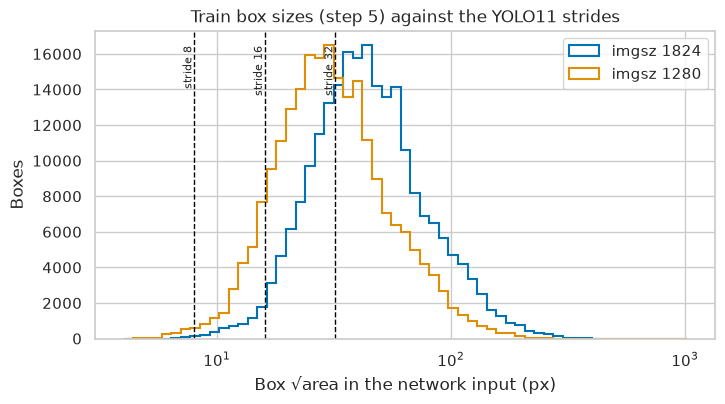

In [11]:
frame_steps = load_frame_steps(PROJECT_ROOT / "config" / "data.toml")
train_frames = select_frames(tables.images.filter(pl.col("split") == "train"), frame_steps["train_tuning"])
train_objects = tables.objects.join(
    train_frames.select("split", "image_id", "width", "height"), on=["split", "image_id"]
)
STRIDES = [8, 16, 32]
input_sizes = pl.concat(
    train_objects.select(
        pl.lit(imgsz).alias("imgsz"),
        ((pl.col("w") * pl.col("h")).sqrt() * imgsz / pl.max_horizontal("width", "height")).alias("sqrt_area_px"),
    )
    for imgsz in (1824, 1280)
)
display(
    input_sizes.group_by("imgsz", maintain_order=True).agg(
        pl.len().alias("boxes"),
        pl.col("sqrt_area_px").median().round(1).alias("median_sqrt_area_px"),
        *((pl.col("sqrt_area_px") < s).mean().round(3).alias(f"share_below_{s}_px") for s in STRIDES),
    )
)
fig, ax = plt.subplots(figsize=(8, 4))
for imgsz in (1824, 1280):
    values = input_sizes.filter(pl.col("imgsz") == imgsz)["sqrt_area_px"].to_numpy()
    ax.hist(values, bins=np.geomspace(4, 1024, 60).tolist(), histtype="step", linewidth=1.5, label=f"imgsz {imgsz}")
for stride in STRIDES:
    ax.axvline(stride, color="black", linestyle="--", linewidth=1)
    ax.text(stride, ax.get_ylim()[1] * 0.95, f"stride {stride}", rotation=90, ha="right", va="top", fontsize=8)
ax.set(xscale="log", xlabel="Box √area in the network input (px)", ylabel="Boxes",
       title="Train box sizes (step 5) against the YOLO11 strides")
ax.legend()
plt.show()

- At `imgsz` 1824 the median train box is 42.9 px (√area) in the network input; 2.3% are below 16 px, 28.2% below 32 px, none below 8 px.
- At `imgsz` 1280 the median is 30.1 px, with 10.4% below 16 px and 54.7% below 32 px: half of the objects become smaller than the stride-32 cell, and one in ten smaller than the stride-16 cell.

### 6.2 Location assignment

For every `train` box at step 5, the grid points of the three strides that lie inside it after the Ultralytics enlargement of sides below 16 px (`src.models.yolo.count_assignment_candidates`, letterbox padding ignored), and how many of those points also lie inside another box of the same frame. The assigner makes at most `topk` of the candidates positive, 10 in the baseline and 20 in `tal_topk`.

In [12]:
def count_candidates(imgsz: int) -> pl.DataFrame:
    parts = []
    for (_, image_id), frame in train_objects.partition_by("split", "image_id", as_dict=True).items():
        scale = imgsz / max(frame["width"][0], frame["height"][0])
        boxes = convert_xywh_to_xyxy(frame.select("x", "y", "w", "h").to_numpy().astype(np.float64)) * scale
        candidates, shared = count_assignment_candidates(boxes, STRIDES, min_side=16)
        parts.append(
            frame.select("image_id", "class_id", "area").with_columns(
                pl.lit(imgsz).alias("imgsz"),
                pl.lit(frame.height).alias("frame_objects"),
                pl.Series("candidates", candidates),
                pl.Series("shared", shared),
            )
        )
    return pl.concat(parts)


candidate_table = pl.concat(count_candidates(imgsz) for imgsz in (1824, 1280))
by_size = pl.concat(
    [
        candidate_table.with_columns(pl.lit("all").alias("size_bucket")),
        explode_size_buckets(candidate_table, pl.col("area")).with_columns(pl.col("size_bucket").cast(pl.String)),
    ]
)
by_size.group_by("imgsz", "size_bucket", maintain_order=True).agg(
    pl.len().alias("boxes"),
    pl.col("candidates").median().alias("median_candidates"),
    (pl.col("candidates") <= 10).mean().round(3).alias("share_at_most_10"),
    (pl.col("candidates") <= 20).mean().round(3).alias("share_at_most_20"),
    (pl.col("shared") / pl.col("candidates")).mean().round(3).alias("mean_shared_share"),
    (pl.col("shared") == pl.col("candidates")).mean().round(3).alias("share_all_shared"),
).sort("imgsz", pl.col("size_bucket").cast(pl.Enum(["all", "small", "medium", "large"])), descending=[True, False])

imgsz,size_bucket,boxes,median_candidates,share_at_most_10,share_at_most_20,mean_shared_share,share_all_shared
i32,str,u32,f64,f64,f64,f64,f64
1824,"""all""",224655,38.0,0.094,0.273,0.244,0.024
1824,"""small""",55970,13.0,0.341,0.787,0.235,0.041
1824,"""medium""",142855,46.0,0.014,0.122,0.269,0.022
1824,"""large""",25912,252.0,0.0,0.0,0.126,0.001
1280,"""all""",224655,19.0,0.27,0.534,0.257,0.034
1280,"""small""",55970,8.0,0.767,0.992,0.271,0.062
1280,"""medium""",142855,22.0,0.124,0.452,0.274,0.029
1280,"""large""",25912,125.0,0.0,0.0,0.126,0.001


- At `imgsz` 1824 a box has a median of 38 candidate points (small 13, medium 46, large 252). 34.1% of small boxes have at most 10 candidates, so topk 10 already takes all of them; 78.7% have at most 20.
- On average 24.4% of a box's candidate points also lie in another box and are contested (small 23.5%, medium 26.9%, large 12.6%); for 4.1% of small boxes every candidate is contested.
- At `imgsz` 1280 small boxes have a median of 8 candidates and 76.7% have at most 10: the assigner has hardly any choice for them.

In [13]:
(
    candidate_table.filter(pl.col("imgsz") == 1824)
    .with_columns(
        pl.when(pl.col("frame_objects") < 25).then(pl.lit("1 to 24"))
        .when(pl.col("frame_objects") < 50).then(pl.lit("25 to 49"))
        .when(pl.col("frame_objects") < 100).then(pl.lit("50 to 99"))
        .otherwise(pl.lit("100 or more"))
        .alias("objects_in_frame")
    )
    .group_by("objects_in_frame")
    .agg(
        pl.col("image_id").n_unique().alias("frames"),
        pl.len().alias("boxes"),
        pl.col("candidates").median().alias("median_candidates"),
        (pl.col("shared") / pl.col("candidates")).mean().round(3).alias("mean_shared_share"),
        (pl.col("shared") == pl.col("candidates")).mean().round(3).alias("share_all_shared"),
    )
    .sort(pl.col("objects_in_frame").cast(pl.Enum(["1 to 24", "25 to 49", "50 to 99", "100 or more"])))
)

objects_in_frame,frames,boxes,median_candidates,mean_shared_share,share_all_shared
str,u32,u32,f64,f64,f64
"""1 to 24""",1414,19479,47.0,0.193,0.019
"""25 to 49""",1662,63887,44.0,0.225,0.022
"""50 to 99""",1450,93159,40.0,0.24,0.025
"""100 or more""",393,48130,24.0,0.301,0.026


- In frames with 100 or more objects a box has a median of 24 candidates against 47 in frames with fewer than 25 objects, and 30.1% of its candidates are contested against 19.3%.
- Dense scenes therefore give each object fewer and more contested locations; this is where the assignment and the strides limit YOLO.

## 7. Failure analysis

The tuned YOLO11s against the tuned Faster R-CNN on all `val` frames, from their `val_predictions.parquet` (`src.evaluation.failure_analysis`). Detections are matched greedily in descending score order, class-aware, at IoU 0.5; detections at least half inside an ignored region are excluded from the counts.

### 7.1 Recall by object size

Share of GT boxes matched by any kept detection (up to 500 per frame), per COCO size bucket. This is the recall ceiling of the AP computation at IoU 0.5.

size_bucket,objects,matched,recall,experiment
str,i64,i64,f64,str
"""all""",105240,87297,0.83,"""yolo-baseline"""
"""small""",20584,14364,0.698,"""yolo-baseline"""
"""medium""",72385,61908,0.855,"""yolo-baseline"""
"""large""",12311,11059,0.898,"""yolo-baseline"""
"""all""",105240,86983,0.827,"""faster_rcnn-giou_loss"""
"""small""",20584,13672,0.664,"""faster_rcnn-giou_loss"""
"""medium""",72385,61410,0.848,"""faster_rcnn-giou_loss"""
"""large""",12311,11940,0.97,"""faster_rcnn-giou_loss"""


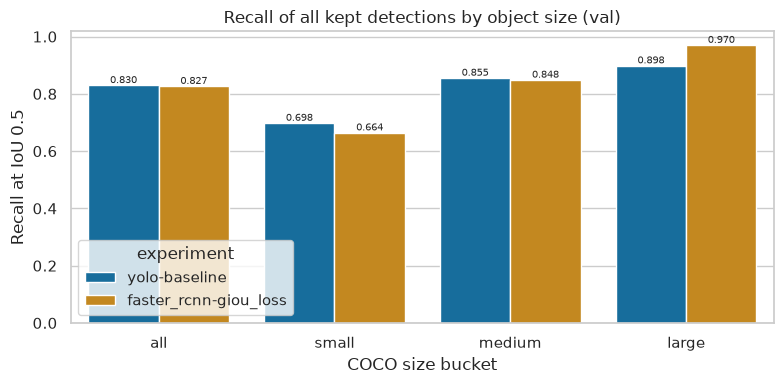

In [14]:
ANALYSED = list(dict.fromkeys([TUNED, TUNED_FASTER_RCNN]))
val_predictions = {e: pl.read_parquet(run_dirs[e] / PREDICTIONS_FILE) for e in ANALYSED}
matches = {e: match_detections(tables, "val", val_predictions[e]) for e in ANALYSED}
recall_by_size = pl.concat(
    compute_recall_by_size(matches[e]).with_columns(pl.lit(e).alias("experiment"))
    for e in ANALYSED
)
fig = plot_grouped_bars(
    recall_by_size,
    "size_bucket",
    "recall",
    "experiment",
    ("COCO size bucket", "Recall at IoU 0.5", "Recall of all kept detections by object size (val)"),
    "{:.3f}",
)
recall_by_size.with_columns(pl.col("recall").round(3))

- YOLO11s matches 83.0% of val GT boxes at IoU 0.5 (small 69.8%, medium 85.5%, large 89.8%) against 82.7% for the tuned Faster R-CNN (66.4%, 84.8%, 97.0%).
- YOLO finds more small objects than Faster R-CNN but misses 10.2% of large boxes, three times as many.

### 7.2 Error breakdown at the best-F1 threshold

The score threshold that maximizes F1 at IoU 0.5 on `val` (ignored detections excluded), then one category per detection above it: correct, duplicate (same-class GT already matched), wrong class, poor localisation (best IoU in [0.1, 0.5)), background (best IoU < 0.1); misses are GT boxes left unmatched.

In [15]:
thresholds = pl.DataFrame(
    [{"experiment": e, **find_best_f1_threshold(matches[e])} for e in ANALYSED]
)
error_counts = pl.concat(
    count_error_categories(matches[e], thresholds.filter(pl.col("experiment") == e)["threshold"].item())
    .with_columns(pl.lit(e).alias("experiment"))
    for e in ANALYSED
)
display(thresholds.with_columns(pl.col("threshold", "precision", "recall", "f1").round(3)))
error_counts.pivot(on="experiment", index="category", values="count")

experiment,threshold,precision,recall,f1
str,f64,f64,f64,f64
"""yolo-baseline""",0.286,0.711,0.622,0.663
"""faster_rcnn-giou_loss""",0.392,0.728,0.658,0.691


category,yolo-baseline,faster_rcnn-giou_loss
str,i64,i64
"""correct""",65463,69272
"""duplicate""",80,240
"""wrong_class""",8755,7908
"""poor_localisation""",7587,8313
"""background""",10251,9381
"""miss""",39777,35968


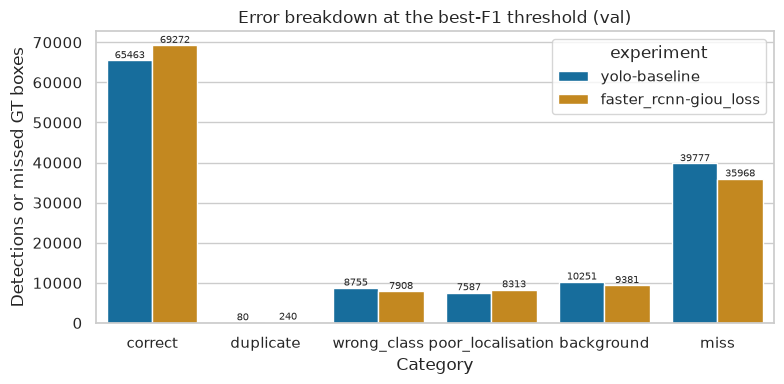

In [16]:
fig = plot_grouped_bars(
    error_counts,
    "category",
    "count",
    "experiment",
    ("Category", "Detections or missed GT boxes", "Error breakdown at the best-F1 threshold (val)"),
    "{:.0f}",
)

- Best-F1 threshold 0.286: precision 0.711, recall 0.622, F1 0.663 (tuned Faster R-CNN 0.691).
- YOLO has the fewest duplicates (80) and fewer poorly localised detections (about 7,600 against 8,300), but more misses at the threshold (about 39,800 against 36,000), more wrong classes (about 8,800 against 7,900), and more background detections (about 10,300 against 9,400).
- The higher recall with all detections but lower recall at the threshold suggests that many of its correct detections have low scores.

In [17]:
tuned_threshold = thresholds.filter(pl.col("experiment") == TUNED)["threshold"].item()
CLASS_BY_ID = dict(enumerate(CLASS_NAMES))
(
    matches[TUNED].detections.filter(
        pl.col("score") >= tuned_threshold, pl.col("category") == "wrong_class"
    )
    .group_by("best_class_id", "class_id")
    .len()
    .sort("len", "best_class_id", "class_id", descending=[True, False, False])
    .head(8)
    .select(
        pl.col("best_class_id").replace_strict(CLASS_BY_ID).alias("gt_class"),
        pl.col("class_id").replace_strict(CLASS_BY_ID).alias("predicted_class"),
        pl.col("len").alias("detections"),
    )
)

gt_class,predicted_class,detections
str,str,u32
"""van""","""car""",1941
"""bicycle""","""motor""",1819
"""motor""","""person""",1131
"""person""","""motor""",638
"""bus""","""truck""",424
"""car""","""van""",363
"""tricycle""","""motor""",344
"""motor""","""tricycle""",325


- The largest confusions are van predicted as car (about 1,940), bicycle as motor (about 1,820), motor as person (about 1,130), person as motor (about 640), and bus as truck (about 420).
- Two-wheelers and their riders account for three of the five largest confusions.

### 7.3 Example frames per category

Tuned model at its best-F1 threshold: the four highest-scoring detections of every error category and four missed GT boxes drawn at random (seed 42), at most one per clip. Each crop is centered on the example, with all GT boxes (yellow), all kept detections (blue), and shaded ignored regions; the example has a thick outline.

category,clip,frame_id,class_name,score,sqrt_area_px
str,str,i64,str,f64,f64
"""correct""","""uav0000137_00458_v""",231,"""van""",0.945,325.7
"""correct""","""uav0000263_03289_v""",332,"""bus""",0.941,216.9
"""correct""","""uav0000339_00001_v""",62,"""van""",0.924,159.9
"""correct""","""uav0000182_00000_v""",224,"""truck""",0.906,77.5
"""duplicate""","""uav0000182_00000_v""",336,"""car""",0.584,56.1
"""duplicate""","""uav0000086_00000_v""",331,"""person""",0.511,34.6
"""duplicate""","""uav0000137_00458_v""",8,"""motor""",0.492,104.8
"""duplicate""","""uav0000305_00000_v""",24,"""car""",0.436,53.6
"""wrong_class""","""uav0000263_03289_v""",50,"""car""",0.903,157.0


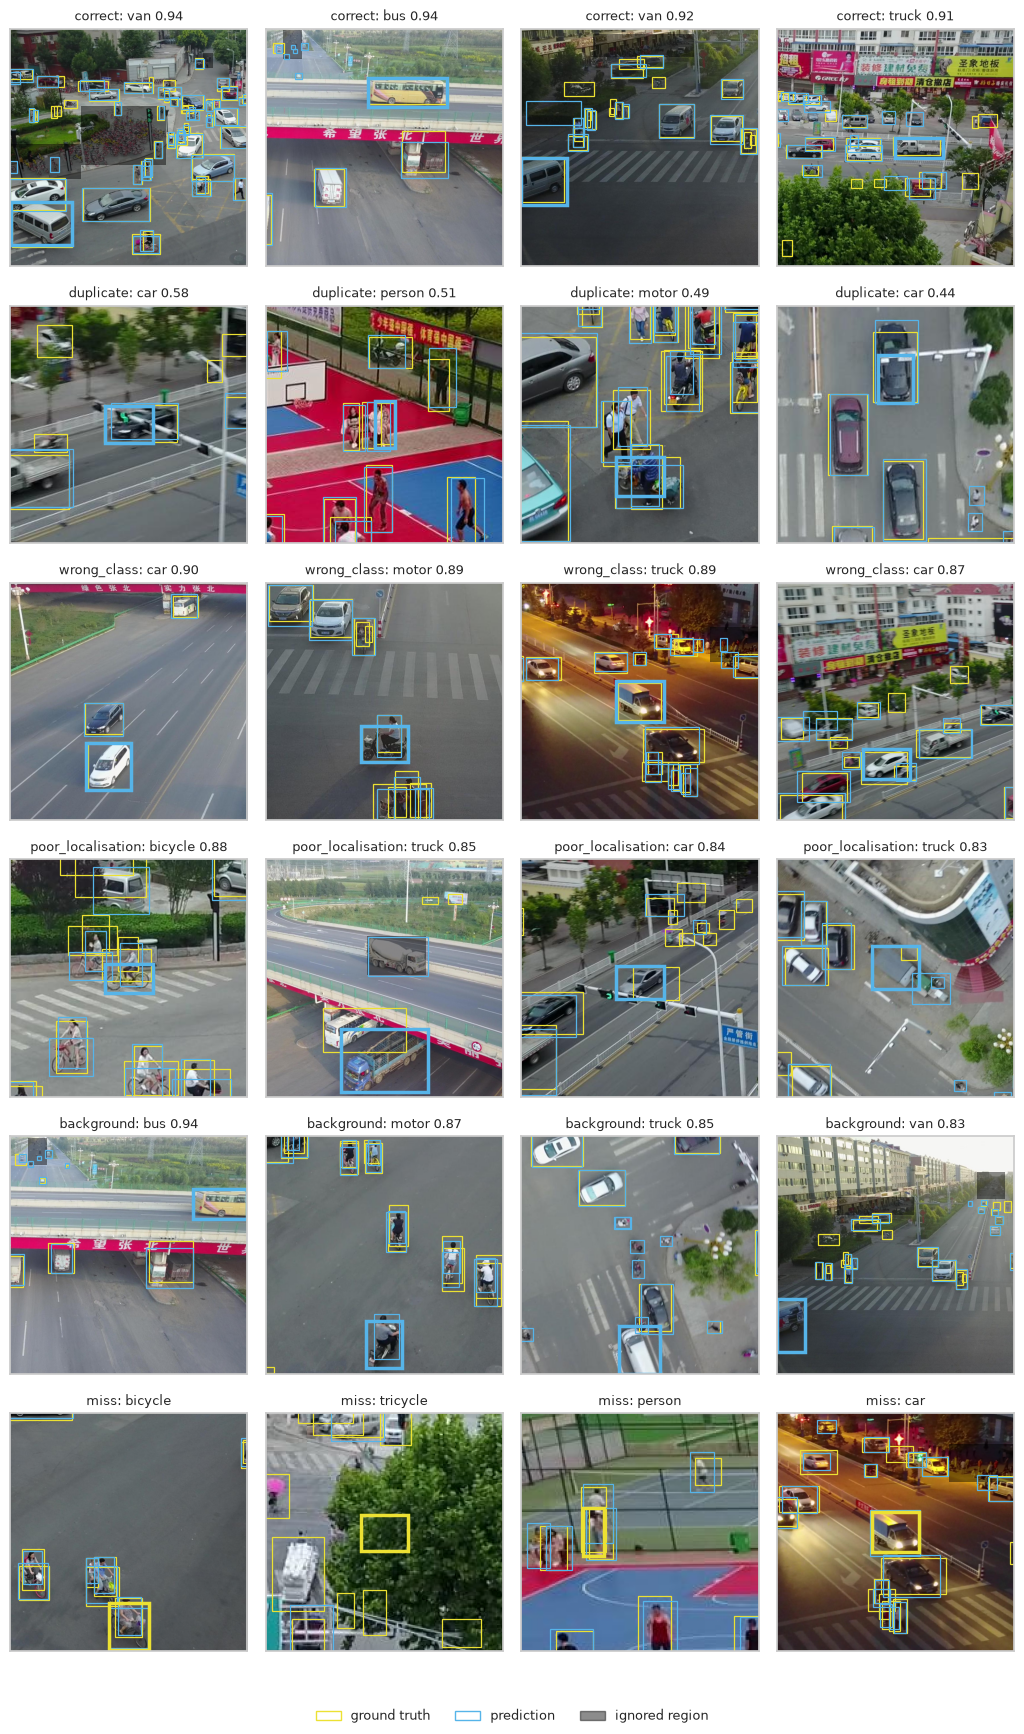

In [18]:
examples = select_error_examples(
    matches[TUNED], val_images, tuned_threshold, per_category=4, seed=SEED
)
fig = plot_error_examples(
    examples,
    val_images,
    val_objects,
    val_ignored,
    val_predictions[TUNED].filter(pl.col("score") >= tuned_threshold),
    context_scale=5.0,
    min_side=96,
)
examples.join(
    val_images.select("image_id", "clip", "frame_id"), on="image_id", maintain_order="left"
).select(
    "category",
    "clip",
    "frame_id",
    pl.col("class_id").replace_strict(CLASS_BY_ID).alias("class_name"),
    pl.col("score").round(3),
    (pl.col("w") * pl.col("h")).sqrt().round(1).alias("sqrt_area_px"),
)

- Correct: large vehicles (van, bus, truck) at scores of about 0.9.
- Duplicate: few and at lower scores (0.44 to 0.58), mostly cars and riders.
- Wrong class: cars predicted on vans and confusion between the two-wheeler classes.
- Poor localisation: boxes on a cyclist and around large vehicles that cover only part of the object or two objects.
- Background: several confident vehicles cut off at the frame edge without a GT box, and riders.
- Miss: objects under trees, riders on two-wheelers, and people standing next to each other.

### 7.4 Failure cases

Four failure cases of the tuned YOLO11s. Counts come from the tables above; the causes are hypotheses.

1. **Large objects are missed**: 10.2% of large boxes against 3.0% for Faster R-CNN, and AP_large is 0.057 lower. Possible causes: mosaic and random scale shrink or crop large objects during training, and the small model (9.4M parameters) has the least capacity of the four.
2. **Correct detections with low scores**: recall with all detections is the highest of the CNN models (83.0%), but at the best-F1 threshold YOLO misses more objects than Faster R-CNN; its scores separate correct and wrong detections less well, which also lowers AP_small (0.112 against 0.120) despite the better small-object recall.
3. **Objects cut off at the frame edge**: several confident background detections are vehicles truncated by the frame border without a GT box; mosaic training shows many objects cut by tile borders, which may make the model confident on truncated objects.
4. **Two-wheelers and riders**: bicycle, motor, and person confusions in both directions; in dense frames the candidate points of a rider and its vehicle are shared (section 6.2), and the assigner gives each point to one of them only.

## 8. Comparison

YOLO11s against the tuned anchor-based detectors (Faster R-CNN `giou_loss` and the tuned RetinaNet) by class and by object size. The augmentation caveat of section 2 applies to every row: YOLO trains with augmentation, the anchor-based families without.

In [19]:
EXTRA_COMPARED = ["retinanet-baseline"]

In [20]:
COMPARED = list(dict.fromkeys([*ANALYSED, *EXTRA_COMPARED]))
per_class_ap = pl.DataFrame(
    {
        "class_name": list(CLASS_NAMES),
        **{
            e: [round(run_metrics[e]["evaluation"]["per_class_ap"][name], 4) for name in CLASS_NAMES]
            for e in COMPARED
        },
    }
)
per_class_ap

class_name,yolo-baseline,faster_rcnn-giou_loss,retinanet-baseline
str,f64,f64,f64
"""person""",0.3124,0.3058,0.2842
"""bicycle""",0.2101,0.2963,0.2183
"""car""",0.4853,0.4858,0.4632
"""van""",0.2,0.2536,0.2159
"""truck""",0.28,0.3167,0.2681
"""tricycle""",0.2663,0.2631,0.1953
"""bus""",0.2621,0.3838,0.4082
"""motor""",0.1207,0.1481,0.0977


- YOLO11s is level with or above the tuned Faster R-CNN on person (0.312 against 0.306), car (0.485 against 0.486), and tricycle (0.266 against 0.263).
- It is far below on bus (0.262 against 0.384), bicycle (0.210 against 0.296), and van (0.200 against 0.254), and above RetinaNet on 5 of 8 classes.

In [21]:
compare_with_reference(
    results.filter(pl.col("experiment").is_in(COMPARED)),
    TUNED_FASTER_RCNN,
    ["map", "map50", "map75", "ap_small", "ap_medium", "ap_large", "ms_per_image"],
).with_columns(pl.selectors.float().round(4))

experiment,map,map50,map75,ap_small,ap_medium,ap_large,ms_per_image,delta_map,delta_map50,delta_map75,delta_ap_small,delta_ap_medium,delta_ap_large,delta_ms_per_image
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""yolo-baseline""",0.2671,0.5242,0.2443,0.1119,0.2483,0.396,13.7118,-0.0395,-0.1016,-0.0207,-0.0084,-0.0441,-0.0571,-47.0644
"""retinanet-baseline""",0.2689,0.5116,0.2559,0.078,0.2347,0.4185,48.6279,-0.0377,-0.1142,-0.0091,-0.0423,-0.0577,-0.0346,-12.1483
"""faster_rcnn-giou_loss""",0.3066,0.6258,0.265,0.1203,0.2924,0.4531,60.7762,0.0,0.0,0.0,0.0,0.0,0.0,0.0


- Against the tuned Faster R-CNN, YOLO11s loses 0.0395 mAP: AP_small −0.0084, AP_medium −0.0441, AP_large −0.0571; the gap grows with object size.
- Against RetinaNet it gains on small objects (AP_small 0.112 against 0.078) and loses on large ones (0.396 against 0.418).
- It is 47 ms per frame faster than Faster R-CNN (13.7 against 60.8 ms). All comparisons carry the augmentation caveat of section 2.

In [22]:
results.filter(pl.col("experiment").str.ends_with("-baseline")).select(
    "experiment", "epochs", "gpu_hours", "map", "map50", "ap_small", "ap_medium", "ap_large",
    "ms_per_image", "public_lb",
).with_columns(pl.col("gpu_hours", "ms_per_image").round(2))

experiment,epochs,gpu_hours,map,map50,ap_small,ap_medium,ap_large,ms_per_image,public_lb
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""yolo-baseline""",20,1.12,0.2671,0.5242,0.1119,0.2483,0.396,13.71,0.20973
"""faster_rcnn-baseline""",10,1.33,0.3013,0.6159,0.1069,0.2744,0.4635,62.54,0.22727
"""retinanet-baseline""",12,1.38,0.2689,0.5116,0.078,0.2347,0.4185,48.63,0.15622
"""rtdetr-baseline""",7,1.43,0.3209,0.6027,0.1334,0.2719,0.4861,53.24,0.25632


Among the baselines YOLO11s is the fastest (13.7 ms/image) and third on the public LB (0.2097), above RetinaNet (0.1562) despite the same val mAP.

## 9. Conclusions

**Results**

- **Baseline.** COCO-pretrained YOLO11s at `imgsz` 1824 reaches 0.2671 mAP, 0.5242 AP50, and 0.1119 AP_small on full val at 13.7 ms/image after 1.12 GPU hours (public LB 0.2097), with Ultralytics' default augmentation (§2, §4).
- **Search.** Input size 1280 instead of 1824 (−0.0173 mAP, 1.7 times faster), TAL topk 20 instead of 10 (±0.0000), and scale gain 0.25 instead of 0.5 (−0.0004): no change beats the baseline, which stays the selected setting (§5).
- **Assignment.** Without anchors, each object gets the grid points inside it as candidates: a median of 38 at `imgsz` 1824, but 13 for small boxes (8 at `imgsz` 1280), and about a quarter of them are shared with another box, 30% in frames with 100 or more objects (§6).
- **Errors and comparison.** YOLO11s has the best small-object recall of the CNN models (69.8%) and the fewest duplicates (80), but misses 10.2% of large boxes; it trails the tuned Faster R-CNN by 0.0084 AP_small and 0.0571 AP_large (§7, §8).

**Hypotheses (not tested here)**

- Small objects are limited by the number of grid points inside them, which shrinks with the input size and with scene density; a stride-4 (P2) level would give them about four times more candidates.
- The cross-family comparison is confounded by augmentation; the anchor-based families trained with similar augmentation would tell how much of YOLO's small-object recall comes from the architecture.